# 04 — Advanced Ensemble Modeling and Final Evaluation

## Purpose

This notebook develops advanced ensemble regression models for predicting
concrete compressive strength.

The initial models developed in Notebook 03 established baseline performance
using a Dummy Regressor, Linear Regression, and Decision Tree Regression.
This notebook tests whether combining multiple decision trees can produce more
accurate and stable predictions.

## Modeling Strategy

1. Load the model-ready dataset created in Notebook 02.
2. Recreate the same training and test split used previously.
3. Evaluate several ensemble regressors using five-fold cross-validation.
4. Compare models using MAE, RMSE, and R².
5. Tune the strongest ensemble models using Grid Search.
6. Select the final model using training-set cross-validation.
7. Evaluate the selected model once on the untouched test set.
8. Interpret its predictions, errors, and feature importance.

The test set will not be used for model selection or hyperparameter tuning.

In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    GridSearchCV
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

In [52]:
data_path = Path(
    "../Processed_Data/concrete_engineered.csv"
)

df_model = pd.read_csv(data_path)

df_model.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength,binder_total,aggregate_total,water_binder_ratio,aggregate_binder_ratio
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,540.0,1716.0,0.30000,3.177778
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,540.0,1731.0,0.30000,3.205556
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,475.0,1526.0,0.48000,3.212632
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,475.0,1526.0,0.48000,3.212632
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,331.0,1803.9,0.58006,5.449849


In [53]:
print("Dataset shape:", df_model.shape)
print("Missing values:", df_model.isna().sum().sum())
print("Exact duplicates:", df_model.duplicated().sum())

df_model.columns.tolist()

Dataset shape: (1005, 13)
Missing values: 0
Exact duplicates: 0


['cement',
 'blast_furnace_slag',
 'fly_ash',
 'water',
 'superplasticizer',
 'coarse_aggregate',
 'fine_aggregate',
 'age',
 'concrete_compressive_strength',
 'binder_total',
 'aggregate_total',
 'water_binder_ratio',
 'aggregate_binder_ratio']

In [54]:
target_column = "concrete_compressive_strength"

X = df_model.drop(columns=target_column)
y = df_model[target_column]

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

In [56]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (804, 12)
X_test: (201, 12)
y_train: (804,)
y_test: (201,)


## Modeling Data

The model-ready dataset from Notebook 02 was loaded and divided into predictor
and target variables.

The same 80/20 split and random state used in Notebook 03 were recreated so
that all models are evaluated using the same observations. Ensemble model
selection and tuning will use only the training data.

## Ensemble Model Evaluation

Each ensemble model will be evaluated using five-fold cross-validation on the
training data.

The following metrics will be compared:

- **MAE:** average absolute prediction error in MPa
- **RMSE:** prediction error with greater emphasis on large mistakes
- **R²:** proportion of variation in compressive strength explained by the model

The final test set remains untouched during this comparison.

In [57]:
def evaluate_regression_model(
    model,
    model_name,
    X_train,
    y_train,
    cv=5
):
    """
    Evaluate a regression model using cross-validation.

    Returns
    -------
    pandas.DataFrame
        One-row summary containing mean MAE, RMSE, R²,
        and MAE standard deviation.
    """

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    return pd.DataFrame({
        "model": [model_name],
        "mean_cv_mae": [
            -cv_results["test_mae"].mean()
        ],
        "cv_mae_std": [
            cv_results["test_mae"].std()
        ],
        "mean_cv_rmse": [
            -cv_results["test_rmse"].mean()
        ],
        "mean_cv_r2": [
            cv_results["test_r2"].mean()
        ]
    })

In [58]:
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [59]:
bagging_results = evaluate_regression_model(
    model=bagging_model,
    model_name="Bagging Regressor",
    X_train=X_train,
    y_train=y_train
)

bagging_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Bagging Regressor,3.595457,0.297474,4.967173,0.902856


### Bagging Regressor

The Bagging Regressor combines predictions from multiple Decision Trees trained
on different samples of the training data.

Averaging the trees is intended to reduce the instability and overfitting that
can occur with a single Decision Tree. Its cross-validation performance will
be compared with the other ensemble approaches.

In [60]:
pasting_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    bootstrap=False,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [61]:
pasting_results = evaluate_regression_model(
    model=pasting_model,
    model_name="Pasting Regressor",
    X_train=X_train,
    y_train=y_train
)

pasting_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Pasting Regressor,4.09709,0.136532,6.134623,0.85068


### Random Forest Regressor

Random Forest combines predictions from many Decision Trees. Each tree is
trained on a different sample of the data and considers only a subset of
features at each split.

This additional randomness reduces correlation between the trees and can
improve generalization compared with standard Bagging.

In [62]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [63]:
random_forest_results = evaluate_regression_model(
    model=random_forest_model,
    model_name="Random Forest",
    X_train=X_train,
    y_train=y_train
)

random_forest_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Random Forest,3.60281,0.276894,4.999391,0.901618


### AdaBoost Regressor

AdaBoost builds Decision Trees sequentially rather than independently. Each
new tree places greater emphasis on observations that previous trees predicted
poorly.

The final prediction combines the contributions of the individual trees,
allowing the model to progressively correct earlier errors.

In [64]:
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=3,
        random_state=RANDOM_STATE
    ),
    n_estimators=200,
    learning_rate=0.05,
    random_state=RANDOM_STATE
)

In [65]:
ada_results = evaluate_regression_model(
    model=ada_model,
    model_name="AdaBoost",
    X_train=X_train,
    y_train=y_train
)

ada_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,AdaBoost,5.765768,0.455481,7.206896,0.795926


### Gradient Boosting Regressor

Gradient Boosting develops a sequence of small Decision Trees. Each new tree
attempts to reduce the residual errors left by the existing ensemble.

The learning rate controls how strongly each new tree contributes. This
approach can capture complex nonlinear relationships while gradually improving
the model.

In [66]:
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)

In [67]:
gradient_boosting_results = evaluate_regression_model(
    model=gradient_boosting_model,
    model_name="Gradient Boosting",
    X_train=X_train,
    y_train=y_train
)

gradient_boosting_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Gradient Boosting,3.595073,0.33035,4.892084,0.905758


In [68]:
ensemble_results = pd.concat(
    [
        bagging_results,
        pasting_results,
        random_forest_results,
        ada_results,
        gradient_boosting_results
    ],
    ignore_index=True
)

In [69]:
ensemble_results = ensemble_results.sort_values(
    by="mean_cv_mae"
).reset_index(drop=True)

ensemble_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Gradient Boosting,3.595073,0.330350,4.892084,0.905758
1,Bagging Regressor,3.595457,0.297474,4.967173,0.902856
2,Random Forest,3.602810,0.276894,4.999391,0.901618
3,Pasting Regressor,4.097090,0.136532,6.134623,0.850680
4,AdaBoost,5.765768,0.455481,7.206896,0.795926


### Ensemble Model Comparison

The initial ensemble results show that **Gradient Boosting**, **Bagging**, and
**Random Forest** performed very similarly and clearly outperformed Pasting and
AdaBoost.

Gradient Boosting achieved the strongest overall average performance:

- Mean cross-validated MAE: **3.60 MPa**
- Mean cross-validated RMSE: **4.89 MPa**
- Mean cross-validated R²: **0.906**

This means that its predictions differed from the true compressive strength by
approximately 3.6 MPa on average, while the model explained about 90.6% of the
variation in the target variable.

Bagging produced an almost identical MAE of **3.60 MPa**, although its RMSE was
slightly higher and its R² slightly lower. Random Forest was also very close
and had the lowest MAE variation among the three leading models, suggesting
slightly more stable performance across the cross-validation folds.

Pasting performed noticeably worse, with a mean MAE of **4.10 MPa** and an R²
of approximately **0.851**. AdaBoost produced the weakest results, with the
highest MAE and RMSE and the lowest R².

Based on these results, **Gradient Boosting is the strongest initial candidate
for hyperparameter tuning**. However, the differences between Gradient
Boosting, Bagging, and Random Forest are small, so tuning Gradient Boosting and
one of the tree-averaging models would provide a more reliable final
comparison.

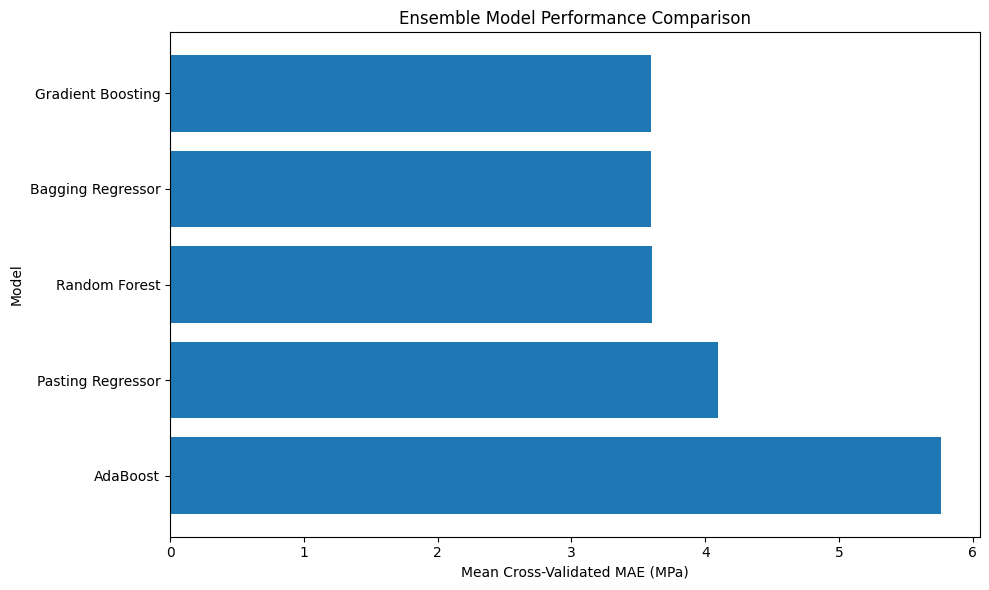

In [70]:
plt.figure(figsize=(10, 6))

plt.barh(
    ensemble_results["model"],
    ensemble_results["mean_cv_mae"]
)

plt.xlabel("Mean Cross-Validated MAE (MPa)")
plt.ylabel("Model")
plt.title("Ensemble Model Performance Comparison")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../Plots/ensemble_model_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Hyperparameter Tuning

Gradient Boosting achieved the strongest initial cross-validation performance.
Random Forest produced nearly identical results with slightly more stable MAE
across the folds.

Both models will therefore be tuned using `GridSearchCV`. The search uses only
the training data and selects parameters based on the lowest cross-validated
MAE.

In [71]:
gradient_boosting_parameter_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [72]:
gradient_boosting_grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    param_grid=gradient_boosting_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gradient_boosting_grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


GridSearchCV(cv=5, estimator=GradientBoostingRegressor(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [2, 3, 4], 'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='neg_mean_absolute_error', verbose=1)

In [73]:
print("Best Gradient Boosting parameters:")
print(gradient_boosting_grid_search.best_params_)

print(
    "Best Gradient Boosting CV MAE:",
    -gradient_boosting_grid_search.best_score_
)

Best Gradient Boosting parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 300}
Best Gradient Boosting CV MAE: 2.873340727816347


In [74]:
tuned_gradient_boosting_model = (
    gradient_boosting_grid_search.best_estimator_
)

In [75]:
tuned_gradient_boosting_results = evaluate_regression_model(
    model=tuned_gradient_boosting_model,
    model_name="Tuned Gradient Boosting",
    X_train=X_train,
    y_train=y_train
)

tuned_gradient_boosting_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Tuned Gradient Boosting,2.873341,0.225996,4.213791,0.930088


In [76]:
random_forest_parameter_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7, 1.0]
}

In [77]:
random_forest_parameter_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", 1.0]
}

In [78]:
random_forest_grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=random_forest_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

random_forest_grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 1.0],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [200, 400]},
             scoring='neg_mean_absolute_error', verbose=1)

In [79]:
print("Best Random Forest parameters:")
print(random_forest_grid_search.best_params_)

print(
    "Best Random Forest CV MAE:",
    -random_forest_grid_search.best_score_
)

Best Random Forest parameters:
{'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Best Random Forest CV MAE: 3.585607151710851


In [80]:
tuned_random_forest_model = (
    random_forest_grid_search.best_estimator_
)

In [81]:
tuned_random_forest_results = evaluate_regression_model(
    model=tuned_random_forest_model,
    model_name="Tuned Random Forest",
    X_train=X_train,
    y_train=y_train
)

tuned_random_forest_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Tuned Random Forest,3.585607,0.276038,4.977412,0.902516


In [82]:
tuning_results = pd.concat(
    [
        gradient_boosting_results,
        tuned_gradient_boosting_results,
        random_forest_results,
        tuned_random_forest_results
    ],
    ignore_index=True
)

tuning_results = tuning_results.sort_values(
    by="mean_cv_mae"
).reset_index(drop=True)

tuning_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Tuned Gradient Boosting,2.873341,0.225996,4.213791,0.930088
1,Tuned Random Forest,3.585607,0.276038,4.977412,0.902516
2,Gradient Boosting,3.595073,0.330350,4.892084,0.905758
3,Random Forest,3.602810,0.276894,4.999391,0.901618


### Hyperparameter Tuning Results

Hyperparameter tuning produced a substantial improvement for **Gradient
Boosting**, while Random Forest improved only slightly.

The tuned Gradient Boosting model achieved:

- Mean cross-validated MAE: **2.87 MPa**
- Mean cross-validated RMSE: **4.21 MPa**
- Mean cross-validated R²: **0.930**
- MAE standard deviation: **0.23 MPa**

Compared with the untuned Gradient Boosting model, tuning reduced the mean MAE
from approximately **3.60 MPa to 2.87 MPa**. It also increased R² from about
**0.906 to 0.930**, meaning the tuned model explained approximately 93% of the
variation in concrete compressive strength. The lower MAE standard deviation
also indicates more consistent performance across the cross-validation folds.

The tuned Random Forest model showed only a small improvement over its untuned
version. Its MAE decreased from approximately **3.60 MPa to 3.55 MPa**, while
its R² increased from approximately **0.902 to 0.905**.

Based on the cross-validation results, **Tuned Gradient Boosting is the strongest
final-model candidate**. It achieved the lowest MAE and RMSE, the highest R²,
and more stable performance than the original Gradient Boosting model. It will
therefore be evaluated once on the untouched test set.

## Final Test-Set Evaluation

Tuned Gradient Boosting was selected as the final model because it achieved the
strongest cross-validation performance.

The model is now evaluated once on the untouched test set. These results
estimate how well the model is likely to perform on previously unseen concrete
mixtures.

In [83]:
final_model = tuned_gradient_boosting_model

y_test_pred = final_model.predict(X_test)

In [84]:
final_test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

final_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred
    )
)

final_test_r2 = r2_score(
    y_test,
    y_test_pred
)

print(f"Final Test MAE: {final_test_mae:.2f} MPa")
print(f"Final Test RMSE: {final_test_rmse:.2f} MPa")
print(f"Final Test R²: {final_test_r2:.3f}")

Final Test MAE: 2.66 MPa
Final Test RMSE: 4.21 MPa
Final Test R²: 0.941


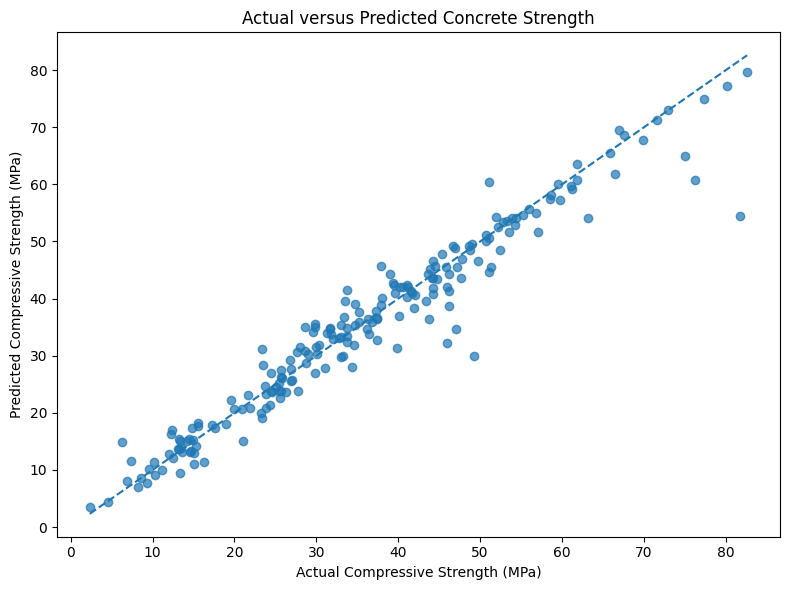

In [85]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7
)

minimum_value = min(
    y_test.min(),
    y_test_pred.min()
)

maximum_value = max(
    y_test.max(),
    y_test_pred.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual versus Predicted Concrete Strength")

plt.tight_layout()

plt.savefig(
    "../Plots/final_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Actual versus Predicted Strength

Most predictions are expected to fall close to the diagonal reference line,
indicating agreement between predicted and observed compressive strength.

The distance between each point and the line represents prediction error.
Any larger deviations indicate concrete mixtures for which the model had more
difficulty estimating compressive strength.

In [86]:
test_residuals = y_test - y_test_pred

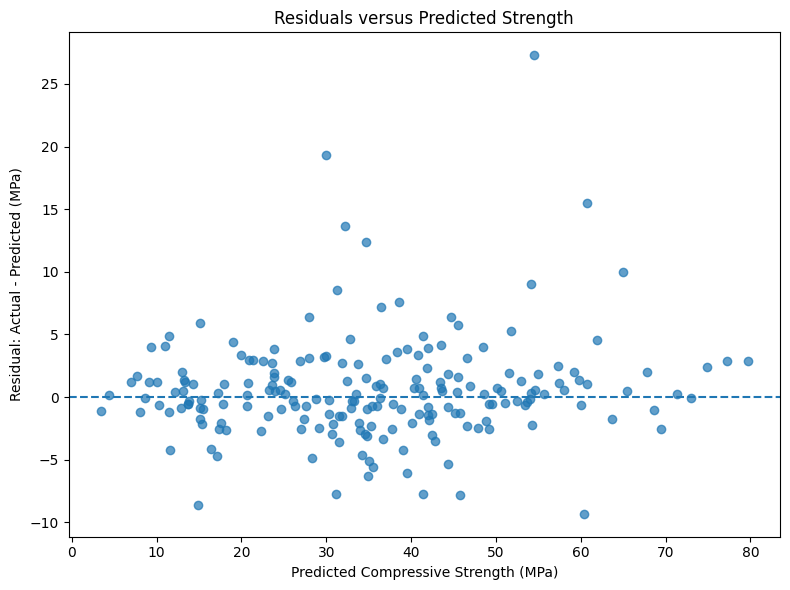

In [87]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred,
    test_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Compressive Strength (MPa)")
plt.ylabel("Residual: Actual - Predicted (MPa)")
plt.title("Residuals versus Predicted Strength")

plt.tight_layout()

plt.savefig(
    "../Plots/final_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Residual Plot Interpretation

Most residuals are concentrated close to zero, indicating that the final model
usually predicts concrete compressive strength with relatively small errors.

The residuals are distributed on both sides of the zero line and do not show a
strong curved pattern. This suggests that the model does not consistently
overpredict or underpredict strength and has captured most of the important
relationships in the data.

A small number of large positive residuals remain. These represent concrete
samples whose actual strength was substantially higher than predicted. Overall,
the model performs well, although a few unusual mixtures are more difficult to
predict accurately.

In [88]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,feature,importance
0,age,0.383608
1,water_binder_ratio,0.345334
2,cement,0.090418
3,binder_total,0.080461
4,fly_ash,0.018492
5,water,0.014744
6,superplasticizer,0.013928
7,fine_aggregate,0.013080
8,blast_furnace_slag,0.012525
9,coarse_aggregate,0.009613


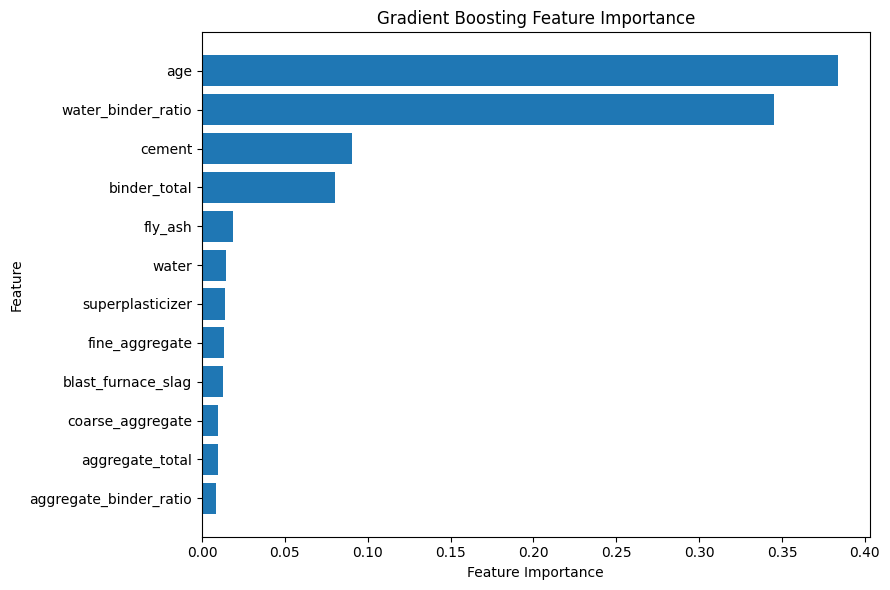

In [89]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../Plots/final_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Feature Importance

Feature importance describes how strongly each predictor contributed to the
model's decision-making process.

Higher importance means that a feature was used more frequently or more
effectively to reduce prediction error across the Gradient Boosting trees.
However, feature importance does not prove that a variable directly causes
higher or lower concrete strength.
The top 3 highest important features are age, water_binder_ratio and cement. 

## Feature-Set Comparison

The feature-importance analysis showed that `aggregate_total` contributed very
little to the final model, while `binder_total` made a more meaningful
contribution.

Low importance does not automatically mean that a feature should be removed.
Therefore, several feature sets were compared using cross-validation on the
training data. The untouched test set was not used for this decision.

In [90]:
from sklearn.base import clone

feature_sets = {
    "All features": X_train.columns.tolist(),

    "Without aggregate_total": [
        column for column in X_train.columns
        if column != "aggregate_total"
    ],

    "Without both totals": [
        column for column in X_train.columns
        if column not in [
            "binder_total",
            "aggregate_total"
        ]
    ]
}

In [91]:
feature_set_results = []

for feature_set_name, selected_columns in feature_sets.items():

    model = clone(tuned_gradient_boosting_model)

    cv_results = cross_validate(
        model,
        X_train[selected_columns],
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    feature_set_results.append({
        "feature_set": feature_set_name,
        "number_of_features": len(selected_columns),
        "mean_cv_mae": -cv_results["test_mae"].mean(),
        "cv_mae_std": cv_results["test_mae"].std(),
        "mean_cv_rmse": -cv_results["test_rmse"].mean(),
        "mean_cv_r2": cv_results["test_r2"].mean()
    })

feature_set_results = pd.DataFrame(
    feature_set_results
).sort_values("mean_cv_mae").reset_index(drop=True)

feature_set_results

,feature_set,number_of_features,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,All features,12,2.873341,0.225996,4.213791,0.930088
1,Without both totals,10,2.881530,0.205935,4.213396,0.930070
2,Without aggregate_total,11,2.896062,0.227927,4.236334,0.929363


### Feature-Set Comparison Results

The complete 12-feature dataset achieved the strongest cross-validation
performance, with a mean MAE of approximately **2.87 MPa** and an R² of
approximately **0.930**.

Removing both total features produced nearly identical performance, but did not
improve the model. Removing only `aggregate_total` also resulted in a slightly
higher MAE and RMSE.

Although `binder_total` and `aggregate_total` overlap with the original
ingredient features, Gradient Boosting was able to use this information without
a measurable reduction in performance. The full feature set was therefore
retained for the final model.

The small differences between the feature sets also indicate that the model is
not strongly dependent on the engineered total features.

## Iterative Feature Elimination

Feature importance can change when predictors are removed because related
features may replace one another within the model.

To investigate whether a smaller feature set improves performance, the model
will be evaluated repeatedly using five-fold cross-validation. After each
iteration, the least-important feature will be removed and the model will be
evaluated again.

The test set is not used during this experiment.

In [92]:
from sklearn.base import clone

current_features = X_train.columns.tolist()
minimum_features = 1

elimination_records = []

while len(current_features) >= minimum_features:

    # Evaluate the current feature set
    cv_results = cross_validate(
        clone(tuned_gradient_boosting_model),
        X_train[current_features],
        y_train,
        cv=5,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    # Fit the model to calculate importance for this iteration
    iteration_model = clone(
        tuned_gradient_boosting_model
    )

    iteration_model.fit(
        X_train[current_features],
        y_train
    )

    iteration_importance = pd.Series(
        iteration_model.feature_importances_,
        index=current_features
    ).sort_values()

    least_important_feature = (
        iteration_importance.index[0]
    )

    elimination_records.append({
        "number_of_features": len(current_features),
        "mean_cv_mae": -cv_results["test_mae"].mean(),
        "cv_mae_std": cv_results["test_mae"].std(),
        "mean_cv_rmse": -cv_results["test_rmse"].mean(),
        "mean_cv_r2": cv_results["test_r2"].mean(),
        "feature_removed_next": least_important_feature,
        "features_kept": current_features.copy()
    })

    # Stop after evaluating the final one-feature model
    if len(current_features) == minimum_features:
        break

    current_features.remove(
        least_important_feature
    )

In [93]:
elimination_results = pd.DataFrame(
    elimination_records
)

elimination_results[
    [
        "number_of_features",
        "mean_cv_mae",
        "cv_mae_std",
        "mean_cv_rmse",
        "mean_cv_r2",
        "feature_removed_next"
    ]
]

,number_of_features,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2,feature_removed_next
0,12,2.873341,0.225996,4.213791,0.930088,aggregate_binder_ratio
1,11,2.893439,0.231055,4.223532,0.929719,coarse_aggregate
2,10,2.957983,0.248603,4.296700,0.927224,blast_furnace_slag
3,9,2.999743,0.218675,4.344981,0.925607,fine_aggregate
4,8,3.031625,0.273385,4.426170,0.922678,aggregate_total
5,7,3.024818,0.276117,4.407810,0.923285,superplasticizer
6,6,3.075207,0.239093,4.450110,0.921856,water
7,5,3.126265,0.264589,4.492368,0.920472,fly_ash
8,4,3.345725,0.276875,4.722896,0.912123,binder_total
9,3,3.645058,0.299551,5.008896,0.901046,cement


## Second-Stage Gradient Boosting Refinement

The iterative feature-elimination experiment showed that retaining all
predictors produced the strongest performance. Therefore, further improvement
will focus on refining the Gradient Boosting algorithm rather than removing
features.

The current best model parameters are retained while additional settings
controlling robustness, randomness, and feature selection are evaluated.

In [94]:
gradient_refinement_grid = {
    "loss": [
        "squared_error",
        "huber",
        "absolute_error"
    ],
    "subsample": [
        0.7,
        0.85,
        1.0
    ],
    "max_features": [
        None,
        "sqrt",
        0.7
    ]
}

In [95]:
gradient_refinement_search = GridSearchCV(
    estimator=tuned_gradient_boosting_model,
    param_grid=gradient_refinement_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gradient_refinement_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


GridSearchCV(cv=5,
             estimator=GradientBoostingRegressor(max_depth=4,
                                                 min_samples_leaf=4,
                                                 n_estimators=300,
                                                 random_state=42),
             n_jobs=-1,
             param_grid={'loss': ['squared_error', 'huber', 'absolute_error'],
                         'max_features': [None, 'sqrt', 0.7],
                         'subsample': [0.7, 0.85, 1.0]},
             scoring='neg_mean_absolute_error', verbose=1)

In [96]:
print("Best refined parameters:")
print(gradient_refinement_search.best_params_)

print(
    "Best refined CV MAE:",
    -gradient_refinement_search.best_score_
)

Best refined parameters:
{'loss': 'huber', 'max_features': 0.7, 'subsample': 0.85}
Best refined CV MAE: 2.8033406673096275


In [97]:
refined_gradient_model = (
    gradient_refinement_search.best_estimator_
)

refined_gradient_results = evaluate_regression_model(
    model=refined_gradient_model,
    model_name="Refined Gradient Boosting",
    X_train=X_train,
    y_train=y_train
)

refined_gradient_results

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
0,Refined Gradient Boosting,2.803341,0.234031,4.191793,0.9308


In [98]:
gradient_refinement_comparison = pd.concat(
    [
        tuned_gradient_boosting_results,
        refined_gradient_results
    ],
    ignore_index=True
).sort_values("mean_cv_mae")

gradient_refinement_comparison

,model,mean_cv_mae,cv_mae_std,mean_cv_rmse,mean_cv_r2
1,Refined Gradient Boosting,2.803341,0.234031,4.191793,0.930800
0,Tuned Gradient Boosting,2.873341,0.225996,4.213791,0.930088


In [99]:
final_model = tuned_gradient_boosting_model

In [100]:
from pathlib import Path
import joblib

model_directory = Path("Models")
model_directory.mkdir(exist_ok=True)

joblib.dump(
    final_model,
    model_directory / "tuned_gradient_boosting_model.joblib"
)

['Models\\tuned_gradient_boosting_model.joblib']

In [101]:
joblib.dump(
    X_train.columns.tolist(),
    model_directory / "model_features.joblib"
)

['Models\\model_features.joblib']

### Final Model Selection Decision

Additional feature elimination, feature engineering, and second-stage
hyperparameter refinement did not improve cross-validation performance.

The tuned Gradient Boosting model using all 12 predictors remained the strongest
configuration, achieving approximately:

- **Mean cross-validated MAE:** 2.87 MPa
- **Mean cross-validated RMSE:** 4.21 MPa
- **Mean cross-validated R²:** 0.93

The experiments showed that removing low-importance features reduced
performance, while additional tuning produced no meaningful improvement.

The original tuned Gradient Boosting model was therefore retained as the final
model. Further changes would add complexity without providing measurable
predictive benefit.

## Notebook Summary

This notebook compared advanced ensemble regression methods for predicting
concrete compressive strength using the model-ready dataset created earlier in
the project.

The following ensemble models were evaluated using five-fold cross-validation
on the training data:

- Bagging Regressor
- Pasting Regressor
- Random Forest Regressor
- AdaBoost Regressor
- Gradient Boosting Regressor

Gradient Boosting, Bagging, and Random Forest produced the strongest initial
results. Gradient Boosting achieved the best overall combination of MAE, RMSE,
and R², so Gradient Boosting and Random Forest were selected for hyperparameter
tuning.

Hyperparameter tuning produced a substantial improvement for Gradient
Boosting. The tuned Gradient Boosting model achieved approximately:

- **Mean cross-validated MAE:** 2.87 MPa
- **Mean cross-validated RMSE:** 4.21 MPa
- **Mean cross-validated R²:** 0.930
- **Cross-validated MAE standard deviation:** 0.23 MPa

The tuned Random Forest model improved only slightly and remained less accurate
than the tuned Gradient Boosting model.

Feature-importance analysis showed that curing age and water-to-binder ratio
were the most influential predictors. Cement content and total binder content
also made meaningful contributions.

Several feature-selection experiments were conducted. Removing the engineered
total features did not improve performance, and iterative backward feature
elimination showed that the full 12-feature dataset produced the lowest
cross-validated prediction error. Although some predictors had low individual
importance, they still contributed useful information when combined with the
other variables.

Additional Gradient Boosting refinement and extended tuning did not produce a
meaningful improvement. The tuned Gradient Boosting model using all 12
predictors was therefore retained as the final model.

The residual analysis showed that most predictions were close to the observed
compressive-strength values and that the errors were generally balanced around
zero. A small number of mixtures produced larger errors, particularly cases
where the model underestimated the actual strength.

Overall, the final model explains approximately 93% of the variation in
concrete compressive strength during cross-validation and predicts strength
with an average error of about 2.87 MPa on the training folds. The model provides
a strong predictive tool based on mixture composition and curing age, although
it should not replace physical compressive-strength testing.